# Contour narration MLP — no-tail targets only
One notebook: reuse labelled sequence caches and the existing split → extract contour features → frozen local DeBERTa context → narration-sequence oversampling → train a small MLP → evaluate/export.

**You run this notebook in godfather.venv.** It does not execute another notebook. Only target units without an explicit Magi text-to-tail link enter the MLP. A tail on any member of a concatenated group bypasses it and forces SPOKEN. Previous two texts on the same page can include tail-linked texts as context.

Targets are SPOKEN=0 / NARRATED=1 from the existing confidently matched GT labels; unknown/unmatched/mixed groups are ignored. No heuristic role or GT context labels enter model inputs. This training experiment uses the established labelled OCR cache; it does not run Gemma artifact classification. Unmatched clutter contributes no supervised loss. Use the same feature extraction on surviving texts when integrating inference later.

Feature caches are fingerprinted and generated below if absent. Existing source caches/checkpoints stay unchanged. Start with all 80 sequences for a comparable split; `MAX_SEQUENCES` is only for extraction smoke checks.

In [1]:
import os,sys,json,hashlib,math,gc,random,importlib.util,re
os.environ['HF_HUB_OFFLINE']='1'
os.environ['TRANSFORMERS_OFFLINE']='1'
import torch
from torch import nn
from torch.utils.data import DataLoader,WeightedRandomSampler
from pathlib import Path
from PIL import Image
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.metrics import precision_recall_fscore_support,f1_score,balanced_accuracy_score

PROJECT=Path('C:/Users/ESHAAN/BYTE/Applied-Task/Magi')
ROOT=PROJECT/'FINETUNING-EXPERMENTS/ContourNarrationMLP'
SOURCE=PROJECT/'FINETUNING-EXPERMENTS/NarrationModelwBubbles/cache_selected_ocr'
SEQUENCES_FILE=SOURCE/'sequences.json'
SPLIT_FILE=SOURCE/'samples.pt'
DEBERTA_PATH=Path('C:/MODELS/deberta-v3-base')
MAGI_PATH=Path('C:/MODELS/magiv2')
BUBBLE_PATH=Path('C:/MODELS/manga_bubbles/bubbles_detect.pt')
HELPER=PROJECT/'paddleOCR-Magi/contour_narrator2.py'
CACHE=ROOT/'cache'
RUN=ROOT/'runs/baseline_seed42'
SEED=42
EPOCHS=40
LR=3e-4
WEIGHT_DECAY=0.01
DROPOUT=0.1
BATCH_SEQUENCES=4
NARRATION_SEQUENCE_WEIGHT=2.5
BETA=0.999
MAX_TOKENS=256
TEXT_BATCH_SIZE=16
MAX_SEQUENCES=None  # None for actual training; a small integer for extraction checks only.
FORCE_CONTOURS=False
FORCE_SEMANTICS=False
DEVICE='cuda' if torch.cuda.is_available() else 'cpu'
BUBBLE_SETTINGS=dict(imgsz=1024,confidence=0.25)
for folder in [CACHE,RUN]:folder.mkdir(parents=True,exist_ok=True)
print('Kernel:',sys.executable,'| Device:',DEVICE)


def digest(value):
    return hashlib.sha256(json.dumps(value,sort_keys=True,ensure_ascii=True,allow_nan=False,default=str).encode()).hexdigest()


def file_hash(path):return hashlib.sha256(Path(path).read_bytes()).hexdigest()


def save_json(path,value):
    path=Path(path);path.parent.mkdir(parents=True,exist_ok=True)
    temp=path.with_suffix(path.suffix+'.tmp')
    temp.write_text(json.dumps(value,ensure_ascii=False,indent=2,allow_nan=False),encoding='utf-8')
    temp.replace(path)


def read_data(path):
    payload=json.loads(Path(path).read_text(encoding='utf-8'))
    if 'data_hash' in payload:assert digest(payload['data'])==payload['data_hash'],f'Bad cache: {path}'
    return payload['data']


def model_identity(path):
    return {str(p.relative_to(path)):[p.stat().st_size,p.stat().st_mtime_ns]
            for p in sorted(Path(path).rglob('*')) if p.is_file()
            and p.suffix in {'.json','.py','.bin','.safetensors'}}


def seed_all(seed):
    random.seed(seed);np.random.seed(seed);torch.manual_seed(seed)
    if torch.cuda.is_available():torch.cuda.manual_seed_all(seed)
seed_all(SEED)


Kernel: c:\Users\ESHAAN\BYTE\godfather.venv\Scripts\python.exe | Device: cuda


## 1. Load existing matched labels and fixed sequence split
The prepared `sequences.json` supplies selected OCR, boxes and GT labels. `samples.pt` supplies the exact original sequence membership; there is no random re-split. These already exist in your environment. If moving this notebook, configure their paths first. Raw detection/bubble/semantic caches needed below are created locally when missing. Duplicate page hashes across train/validation are rejected.

In [2]:
assert SEQUENCES_FILE.is_file(),f'Configure existing labelled sequence cache: {SEQUENCES_FILE}'
assert SPLIT_FILE.is_file(),f'Configure existing split cache: {SPLIT_FILE}'
sequences=json.loads(SEQUENCES_FILE.read_text(encoding='utf-8'))
split_data=torch.load(SPLIT_FILE,map_location='cpu',weights_only=True)
train_ids={split_data['samples'][i]['sequence_id'] for i in split_data['train_indices']}
val_ids={split_data['samples'][i]['sequence_id'] for i in split_data['val_indices']}
assert not train_ids&val_ids
assert {s['sequence_id'] for s in sequences}==train_ids|val_ids,'Source sequence/split mismatch'
del split_data
if MAX_SEQUENCES is not None:sequences=sequences[:int(MAX_SEQUENCES)]
for seq in sequences:
    assert len(seq['pages'])==3,seq['sequence_id']
    for page in seq['pages']:
        assert Path(page['path']).is_file(),page['path']
        assert file_hash(page['path'])==page['sha256'],'Image/cache mismatch'
train_hashes={p['sha256'] for s in sequences if s['sequence_id'] in train_ids for p in s['pages']}
val_hashes={p['sha256'] for s in sequences if s['sequence_id'] in val_ids for p in s['pages']}
assert not train_hashes&val_hashes,'A page is shared between train and validation'
save_json(RUN/'split.json',dict(train=sorted(train_ids),validation=sorted(val_ids)))
print('Available sequences:',len(sequences),'| Original split:',len(train_ids),len(val_ids))


Available sequences: 80 | Original split: 64 16


## 2. Numeric feature contract
Current unit + previous two units on the same page, each with numeric values and per-feature availability flags. Missing values become zero with flag=0. First/second predecessors also have explicit presence flags.

Lengths/bulges are divided by median member-text short side; sampled runs/point counts by 256. `region_area_ratio` uses the selected background mask area divided by member text area. Geometry uses page-normalized center/size. Grouping is an input description only; the output remains SPOKEN/NARRATED. No tail flag, heuristic role, reason string, member GT labels, or raw contour-point list enters the MLP.

In [3]:
FEATURE_NAMES=[
    'white_fraction','solid_fraction','coverage','outside_fraction','region_area_ratio',
    'curved_fraction','flat_fraction','sharp_fraction','curve_run','sharp_run',
    'curve_arc_px','curve_turn_deg','curve_bulge_px','curve_consistency',
    'rectangularity','box_axis_fraction','box_like','strong_curves',
    'visible_points','visible_fraction','visible_support','crop_edge_fraction',
    'leak_suspected','caption_uncertain','retry_attempted','faint_pass',
    'bubble_matched','region_found','individual_outline','merged','member_count',
    'center_x','center_y','width','height']


def numeric_features(group,debug,page,outline_ids):
    values={key:group.get(key) for key in FEATURE_NAMES}
    boxes=group['member_text_boxes']
    scale=max(1,float(np.median([min(b[2]-b[0],b[3]-b[1]) for b in boxes])))
    a,b,c,d=group['text_box'];width=page['width'];height=page['height']
    chosen=debug['chosen']
    values.update(center_x=(a+c)/(2*width),center_y=(b+d)/(2*height),
        width=(c-a)/width,height=(d-b)/height,
        bubble_matched=bool(debug['attempts']),region_found=chosen is not None,
        individual_outline=any(bid in outline_ids for bid in group['box_ids']),
        merged=group['grouping_source']=='overlap_candidate',member_count=len(boxes),
        faint_pass=group.get('extraction_pass')=='faint_barrier')
    if chosen:
        values['region_area_ratio']=chosen['region']['area']/max(1,sum((x2-x1)*(y2-y1) for x1,y1,x2,y2 in boxes))
    for key in ['curve_arc_px','curve_bulge_px']:
        if values[key] is not None:values[key]=float(values[key])/scale
    for key in ['visible_points','curve_run','sharp_run']:
        if values[key] is not None:values[key]=float(values[key])/256
    vector=[];present=[]
    for key in FEATURE_NAMES:
        value=values[key]
        valid=value is not None and np.isfinite(float(value))
        vector.append(float(value) if valid else 0.)
        present.append(float(valid))
    return vector+present


NUMERIC_PER_UNIT=2*len(FEATURE_NAMES)
NUMERIC_DIM=3*NUMERIC_PER_UNIT+2
print('Per-unit numeric values + availability:',NUMERIC_PER_UNIT)
print('Current + previous two + context flags:',NUMERIC_DIM)


Per-unit numeric values + availability: 70
Current + previous two + context flags: 212


## 3. Discover/create raw Magi tails and YOLO bubbles
Uses the original raw cache referenced by each labelled sequence, validating box alignment. Missing raw predictions are generated with local Magi. Tails count only through explicit text-to-tail links. If detection order changes, a unique IoU >= 0.95 match is required; ambiguous alignment stops with a useful error.

YOLO discovery checks compatible full-pipeline page caches, then creates separate experiment caches if missing. Models are loaded lazily and released after extraction.

In [4]:
assert HELPER.is_file() and BUBBLE_PATH.is_file()
spec=importlib.util.spec_from_file_location('contour_mlp_helper',HELPER)
contour=importlib.util.module_from_spec(spec);spec.loader.exec_module(contour)
BUBBLE_SHA=file_hash(BUBBLE_PATH)
HELPER_ID=dict(contour=file_hash(HELPER),grouping=file_hash(HELPER.with_name('contour_grouping.py')))
magi_model=None;bubble_model=None


def plain(value):
    if isinstance(value,torch.Tensor):return value.detach().cpu().tolist()
    if isinstance(value,np.ndarray):return value.tolist()
    if isinstance(value,dict):return {k:plain(v) for k,v in value.items()}
    if isinstance(value,(list,tuple)):return [plain(v) for v in value]
    return value


def raw_sequence(seq):
    global magi_model
    path=Path(seq['raw_cache'])
    if path.is_file():
        raw=read_data(path)
        assert len(raw)==len(seq['pages'])
        if all('text_tail_associations' in p and 'tails' in p for p in raw):return raw
    identity=dict(pages=seq['pages'],model=str(MAGI_PATH),files=model_identity(MAGI_PATH),algorithm=1)
    path=CACHE/'raw'/(digest(identity)+'.json')
    if path.is_file():return read_data(path)
    if magi_model is None:
        from transformers import AutoConfig,AutoModel
        config=AutoConfig.from_pretrained(str(MAGI_PATH),trust_remote_code=True,local_files_only=True)
        config.detection_model_config.use_pretrained_backbone=False
        config.disable_ocr=False;config.disable_detections=False
        magi_model=AutoModel.from_pretrained(str(MAGI_PATH),config=config,trust_remote_code=True,
            local_files_only=True).to(DEVICE).eval()
    raw=[]
    for page in seq['pages']:
        with Image.open(page['path']) as im:array=np.asarray(im.convert('L').convert('RGB'))
        with torch.inference_mode():prediction=magi_model.do_chapter_wide_prediction([array],{'images':[],'names':[]},do_ocr=False)[0]
        raw.append(plain({key:prediction[key] for key in ['texts','tails','text_tail_associations']}))
    save_json(path,dict(data=raw,data_hash=digest(raw)))
    return raw


def tail_text_ids(raw,boxes):
    ids=set();used=set()
    for box in boxes:
        index=box['text_index']
        if not (index<len(raw['texts']) and np.allclose(raw['texts'][index],box['bbox'],atol=.05,rtol=0)):
            a=box['bbox'];scores=[]
            for b in raw['texts']:
                overlap=max(0,min(a[2],b[2])-max(a[0],b[0]))*max(0,min(a[3],b[3])-max(a[1],b[1]))
                scores.append(overlap/max(1,(a[2]-a[0])*(a[3]-a[1])+(b[2]-b[0])*(b[3]-b[1])-overlap))
            matches=[i for i,v in enumerate(scores) if v>=.95]
            assert len(matches)==1,f"Cannot uniquely align tails for {box['box_id']}"
            index=matches[0]
        assert index not in used,'Duplicate text alignment';used.add(index)
        links=[int(t) for text,t in raw['text_tail_associations'] if int(text)==index]
        assert all(0<=t<len(raw['tails']) for t in links),'Invalid tail index'
        if links:ids.add(box['box_id'])
    return ids


# Build a read-only index once, rather than scanning every cache for every page.
bubble_sources={}
for manifest_path in (PROJECT/'paddleOCR-Magi/cache_contour_full_inference').rglob('manifest.json'):
    try:
        manifest=json.loads(manifest_path.read_text(encoding='utf-8'))
        settings=manifest['stages']['contour_bubbles']['settings']
        if settings['weights_sha256']!=BUBBLE_SHA or settings['settings']!=BUBBLE_SETTINGS:continue
        for i,page in enumerate(manifest['inputs']['pages']):
            bubble_sources[page['sha256']]=(manifest_path.with_name('contour_bubbles.json'),i)
    except (OSError,KeyError,ValueError,TypeError):continue


def page_bubbles(page):
    global bubble_model
    key=digest(dict(page=page['sha256'],weights=BUBBLE_SHA,settings=BUBBLE_SETTINGS))
    path=CACHE/'bubbles'/(key+'.json')
    if path.is_file():return read_data(path)
    if page['sha256'] in bubble_sources:
        source,index=bubble_sources[page['sha256']]
        candidates=read_data(source)[index]['candidates']
    else:
        from ultralytics import YOLO
        if bubble_model is None:bubble_model=YOLO(str(BUBBLE_PATH))
        with Image.open(page['path']) as image:
            prediction=bubble_model.predict(source=image.convert('RGB'),imgsz=BUBBLE_SETTINGS['imgsz'],
                conf=BUBBLE_SETTINGS['confidence'],device=0 if DEVICE=='cuda' else 'cpu',verbose=False)[0]
        candidates=[]
        for box,score in zip(prediction.boxes.xyxy.cpu().tolist(),prediction.boxes.conf.cpu().tolist()):
            a,b,c,d=box
            bounds=[max(0,math.floor(a)),max(0,math.floor(b)),min(page['width'],math.ceil(c)),min(page['height'],math.ceil(d))]
            if bounds[2]>bounds[0] and bounds[3]>bounds[1]:candidates.append(dict(box=bounds,confidence=float(score)))
        candidates.sort(key=lambda r:(r['box'][1],-r['box'][0]))
        del prediction
    save_json(path,dict(data=candidates,data_hash=digest(candidates)))
    return candidates


## 4. Cache contour units and labels
Use the same `analyze_page` implementation as the contour pipeline. Every unit retains its member IDs. A group is supervised only when all members have known, agreeing GT roles. Tail-linked units get training label -100 and are never sent as targets to the MLP. They can still be earlier context.

For this learned experiment, retain the measured features even when the heuristic says uncertain/leaking; the MLP learns their interpretation. Heuristic role/reason are saved for comparison only.

In [5]:
unit_sequences=[]
try:
    for seq in sequences:
        raw=raw_sequence(seq)
        signature=digest(dict(source=seq,raw=digest(raw),helper=HELPER_ID,bubbles=BUBBLE_SHA,
            bubble_settings=BUBBLE_SETTINGS,check=contour.CHECK,region=contour.REGION,
            faint=contour.FAINT_REGION,group_faint=contour.contours.FAINT,features=FEATURE_NAMES,algorithm=1))
        path=CACHE/'units'/(seq['sequence_id']+'.json')
        payload=json.loads(path.read_text(encoding='utf-8')) if path.is_file() else None
        if payload and payload['signature']==signature and not FORCE_CONTOURS:
            assert digest(payload['data'])==payload['data_hash']
            unit_sequences.append(payload['data']);print('REUSE',seq['sequence_id']);continue
        units=[]
        for page_index,page in enumerate(seq['pages']):
            boxes=sorted([b for b in seq['boxes'] if b['page_index']==page_index],key=lambda b:b['text_index'])
            linked=tail_text_ids(raw[page_index],boxes)
            lookup={b['box_id']:b for b in boxes}
            texts=[dict(box_id=b['box_id'],text_index=b['text_index'],box=b['bbox'],text=b['ocr'],
                magi_text=b.get('magi_ocr',b['ocr']),paddle_text=b.get('ocr_selection',{}).get('paddle_text',''),
                ocr_agreement=None) for b in boxes if str(b['ocr'] or '').strip()]
            with Image.open(page['path']) as image:
                analysis,debug=contour.analyze_page(page_bubbles(page),image.convert('RGB'),texts,page_index+1)
            outlines={bid for c in analysis['grouping']['individual'] if c['boundary_found'] for bid in c['text_ids']}
            for group,detail in zip(analysis['rows'],debug):
                members=[lookup[bid] for bid in group['box_ids']]
                labels=[int(b['label']) for b in members]
                gt=labels[0] if labels and all(label in [0,1] and label==labels[0] for label in labels) else -100
                has_tail=any(bid in linked for bid in group['box_ids'])
                units.append(dict(sequence_id=seq['sequence_id'],box_id=group['box_id'],box_ids=group['box_ids'],
                    page_index=page_index,text_index=group['text_index'],text=group['text'],
                    gt_label=gt,label=-100 if has_tail else gt,has_tail=has_tail,
                    numeric=numeric_features(group,detail,page,outlines),
                    heuristic_role=group['text_role'],heuristic_reason=group['reason']))
        item=dict(sequence_id=seq['sequence_id'],signature=signature,units=units)
        save_json(path,dict(signature=signature,data=item,data_hash=digest(item)))
        unit_sequences.append(item);print('CREATE',seq['sequence_id'],len(units),'units')
finally:
    magi_model=None;bubble_model=None;gc.collect()
    if torch.cuda.is_available():torch.cuda.empty_cache()
print('No-tail labeled targets:',sum(u['label'] in [0,1] for s in unit_sequences for u in s['units']))


CREATE seq_2032620aa4e4ac7f 16 units
CREATE seq_952f154fb1505883 30 units
CREATE seq_7db7a000adeceacf 30 units
CREATE seq_9032e5551cf1a9d2 36 units
CREATE seq_2022b8c0e1f2d3c0 24 units
CREATE seq_a3bd36201a0cd61b 34 units
CREATE seq_72fdfff4b4353a42 30 units
CREATE seq_b251c8e1ba8b91f8 26 units
CREATE seq_ee880b9612205860 27 units
CREATE seq_06ec0acde37dffa4 33 units
CREATE seq_1c1d4f5e71a2f554 26 units
CREATE seq_032cbb4dc8686963 30 units
CREATE seq_f164203a45862778 32 units
CREATE seq_dcebdbbf614a9b4d 27 units
CREATE seq_2fae297a18af2a57 25 units
CREATE seq_d8afceb0e8f9122d 17 units
CREATE seq_f7ee32f1dd417802 11 units
CREATE seq_d62d309820d28efa 12 units
CREATE seq_210721b0d576149f 11 units
CREATE seq_e8b4f75454f9491f 15 units
CREATE seq_b136f32c2233b97c 13 units
CREATE seq_27e88136c1812f85 12 units
CREATE seq_d7af6c64ebc22bbe 17 units
CREATE seq_96839890d69d7698 12 units
CREATE seq_b3247b4b3a2f591b 7 units
CREATE seq_b9b5a9ad9a64ced9 27 units
CREATE seq_f1c007d2d64e6aad 8 units
CRE

## 5. Frozen DeBERTa: previous two texts + target
A separate history per page, including tail-linked/context-only units. Pool target tokens only. These are frozen features; this notebook does not fine-tune DeBERTa. Semantic cache identity includes encoder files, contour unit text/order, token budget and pooling. No Hugging Face downloads.

In [6]:
assert DEBERTA_PATH.is_dir(),DEBERTA_PATH
TEXT_ID=model_identity(DEBERTA_PATH)
encoder=None;tokenizer=None
try:
    for seq in unit_sequences:
        signature=digest(dict(units=[(u['box_id'],u['page_index'],u['text']) for u in seq['units']],
            model=str(DEBERTA_PATH),files=TEXT_ID,max_tokens=MAX_TOKENS,context=2,pool='target_mean_v1'))
        path=CACHE/'semantics'/(seq['sequence_id']+'.pt')
        saved=torch.load(path,map_location='cpu',weights_only=True) if path.is_file() else None
        if saved and saved['signature']==signature and not FORCE_SEMANTICS:
            seq['semantic']=saved['vectors'];continue
        if encoder is None:
            from transformers import AutoTokenizer,AutoModel
            tokenizer=AutoTokenizer.from_pretrained(str(DEBERTA_PATH),local_files_only=True)
            encoder=AutoModel.from_pretrained(str(DEBERTA_PATH),local_files_only=True).to(DEVICE).eval()
            encoder.requires_grad_(False)
            assert encoder.config.hidden_size==768
        history={0:[],1:[],2:[]};items=[]
        for unit in seq['units']:
            context=[]
            for text in history[unit['page_index']][-2:]:
                context+=tokenizer.encode(text,add_special_tokens=False)+[tokenizer.sep_token_id]
            target=tokenizer.encode(unit['text'],add_special_tokens=False) or [tokenizer.unk_token_id]
            budget=MAX_TOKENS-2;assert budget>0
            target=target[-budget:];remaining=budget-len(target)
            context=context[-remaining:] if remaining else []
            ids=[tokenizer.cls_token_id]+context+target+[tokenizer.sep_token_id]
            mask=[0]*(1+len(context))+[1]*len(target)+[0]
            items.append((ids,mask));history[unit['page_index']].append(unit['text'])
        vectors=[]
        with torch.inference_mode():
            for start in range(0,len(items),TEXT_BATCH_SIZE):
                batch=items[start:start+TEXT_BATCH_SIZE];length=max(len(v[0]) for v in batch)
                ids=torch.full((len(batch),length),tokenizer.pad_token_id,dtype=torch.long,device=DEVICE)
                attention=torch.zeros_like(ids);target_mask=torch.zeros_like(ids,dtype=torch.float)
                for i,(tokens,mask) in enumerate(batch):
                    ids[i,:len(tokens)]=torch.tensor(tokens,device=DEVICE)
                    attention[i,:len(tokens)]=1;target_mask[i,:len(tokens)]=torch.tensor(mask,device=DEVICE)
                hidden=encoder(input_ids=ids,attention_mask=attention).last_hidden_state
                pooled=(hidden*target_mask.unsqueeze(-1)).sum(1)/target_mask.sum(1,keepdim=True)
                vectors.extend(pooled.float().cpu().unbind())
        matrix=torch.stack(vectors) if vectors else torch.empty(0,768)
        path.parent.mkdir(parents=True,exist_ok=True)
        torch.save(dict(signature=signature,vectors=matrix),path)
        seq['semantic']=matrix;print('SEMANTICS',seq['sequence_id'],len(matrix))
finally:
    encoder=None;tokenizer=None;gc.collect()
    if torch.cuda.is_available():torch.cuda.empty_cache()


c:\Users\ESHAAN\BYTE\godfather.venv\Lib\site-packages\transformers\convert_slow_tokenizer.py:566: UserWarning: The sentencepiece tokenizer that you are converting to a fast tokenizer uses the byte fallback option which is not implemented in the fast tokenizers. In practice this means that the fast version of the tokenizer can produce unknown tokens whereas the sentencepiece version would have converted these unknown tokens into a sequence of byte tokens matching the original piece of text.
  warnings.warn(
The tokenizer you are loading from 'C:\MODELS\deberta-v3-base' with an incorrect regex pattern: https://huggingface.co/mistralai/Mistral-Small-3.1-24B-Instruct-2503/discussions/84#69121093e8b480e709447d5e. This will lead to incorrect tokenization. You should set the `fix_mistral_regex=True` flag when loading this tokenizer to fix this issue.
c:\Users\ESHAAN\BYTE\godfather.venv\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch 

SEMANTICS seq_2032620aa4e4ac7f 16
SEMANTICS seq_952f154fb1505883 30
SEMANTICS seq_7db7a000adeceacf 30
SEMANTICS seq_9032e5551cf1a9d2 36
SEMANTICS seq_2022b8c0e1f2d3c0 24
SEMANTICS seq_a3bd36201a0cd61b 34
SEMANTICS seq_72fdfff4b4353a42 30
SEMANTICS seq_b251c8e1ba8b91f8 26
SEMANTICS seq_ee880b9612205860 27
SEMANTICS seq_06ec0acde37dffa4 33
SEMANTICS seq_1c1d4f5e71a2f554 26
SEMANTICS seq_032cbb4dc8686963 30
SEMANTICS seq_f164203a45862778 32
SEMANTICS seq_dcebdbbf614a9b4d 27
SEMANTICS seq_2fae297a18af2a57 25
SEMANTICS seq_d8afceb0e8f9122d 17
SEMANTICS seq_f7ee32f1dd417802 11
SEMANTICS seq_d62d309820d28efa 12
SEMANTICS seq_210721b0d576149f 11
SEMANTICS seq_e8b4f75454f9491f 15
SEMANTICS seq_b136f32c2233b97c 13
SEMANTICS seq_27e88136c1812f85 12
SEMANTICS seq_d7af6c64ebc22bbe 17
SEMANTICS seq_96839890d69d7698 12
SEMANTICS seq_b3247b4b3a2f591b 7
SEMANTICS seq_b9b5a9ad9a64ced9 27
SEMANTICS seq_f1c007d2d64e6aad 8
SEMANTICS seq_b8b5563330fdc89d 30
SEMANTICS seq_dce8be23c3281228 16
SEMANTICS seq_f4

## 6. Join current/previous numeric features; fit normalization on training targets only
No-tail labelled targets only are used to fit feature mean/std. Prior tail-linked or unlabeled texts can provide context, but their labels are never inputs. Missing predecessor slots are zero with presence flags. Train/validation membership is copied from the original split.

Narration-containing **whole sequences** receive sampling weight 2.5 by default, with replacement. No boxes are duplicated inside a sequence. Class weights use original no-tail training counts before oversampling: `(1-beta)/(1-beta**count)`, normalized to mean one.

In [7]:
samples=[]
for seq in unit_sequences:
    units=seq['units'];history={0:[],1:[],2:[]};numeric=[]
    for unit in units:
        previous=history[unit['page_index']]
        zero=[0.]*NUMERIC_PER_UNIT
        prev2=previous[-2] if len(previous)>=2 else zero
        prev1=previous[-1] if previous else zero
        numeric.append(unit['numeric']+prev2+prev1+[float(len(previous)>=2),float(bool(previous))])
        previous.append(unit['numeric'])
    sample=dict(sequence_id=seq['sequence_id'],units=units,
        numeric=np.asarray(numeric,dtype=np.float32).reshape(-1,NUMERIC_DIM),
        semantic=seq['semantic'].float(),labels=np.array([u['label'] for u in units],dtype=np.int64))
    assert sample['semantic'].shape==(len(units),768)
    assert np.isfinite(sample['numeric']).all() and torch.isfinite(sample['semantic']).all()
    assert all(u['label']==-100 for u in units if u['has_tail'])
    samples.append(sample)
train=[s for s in samples if s['sequence_id'] in train_ids and np.isin(s['labels'],[0,1]).any()]
val=[s for s in samples if s['sequence_id'] in val_ids]
assert train and val,'Use the complete sequence set; extraction smoke subsets may miss validation'
train_numeric=np.concatenate([s['numeric'][np.isin(s['labels'],[0,1])] for s in train])
mean=torch.tensor(train_numeric.mean(0));std=torch.tensor(train_numeric.std(0)).clamp_min(1e-6)
labels=np.concatenate([s['labels'][s['labels']!=-100] for s in train])
counts=np.bincount(labels,minlength=2)
val_counts=np.bincount([u['gt_label'] for s in val for u in s['units'] if not u['has_tail'] and u['gt_label'] in [0,1]],minlength=2)
assert (counts>0).all() and (val_counts>0).all(),'Both classes required in no-tail train/validation targets'
assert 0<=BETA<1
weights=np.ones(2) if BETA==0 else (1-BETA)/(-np.expm1(counts*np.log(BETA)))
class_weights=torch.tensor(weights/weights.mean(),dtype=torch.float32,device=DEVICE)
sequence_weights=[NARRATION_SEQUENCE_WEIGHT if (s['labels']==1).any() else 1. for s in train]
assert NARRATION_SEQUENCE_WEIGHT>0
sampler=WeightedRandomSampler(sequence_weights,num_samples=len(train),replacement=True,
    generator=torch.Generator().manual_seed(SEED))


def collate_no_tail(batch):
    numeric=[];semantic=[];labels=[]
    for sample in batch:
        keep=np.isin(sample['labels'],[0,1])
        indices=np.flatnonzero(keep)
        assert all(not sample['units'][i]['has_tail'] for i in indices),'Tail target reached MLP'
        numeric.append(torch.from_numpy(sample['numeric'][keep]))
        semantic.append(sample['semantic'][torch.tensor(indices)])
        labels.append(torch.from_numpy(sample['labels'][keep]))
    return torch.cat(numeric),torch.cat(semantic),torch.cat(labels)


loader=DataLoader(train,batch_size=BATCH_SEQUENCES,sampler=sampler,collate_fn=collate_no_tail,num_workers=0)
display(pd.DataFrame([dict(split='train',spoken=int(counts[0]),narrated=int(counts[1])),
    dict(split='validation',spoken=int(val_counts[0]),narrated=int(val_counts[1]))]))
print('Train sequences with no-tail labels:',len(train),'| Validation sequences:',len(val))
print('Sequence sampling weights:',pd.Series(sequence_weights).value_counts().to_dict())
print('Class weights:',class_weights.cpu().tolist())
print('Tail-linked units excluded from MLP targets:',sum(u['has_tail'] for s in samples for u in s['units']))
print('Known GT narration with a tail (hard-rule conflicts):',sum(u['has_tail'] and u['gt_label']==1 for s in samples for u in s['units']))
# Illustrate one deterministic sampler draw without consuming the actual training sampler state.
preview=WeightedRandomSampler(sequence_weights,len(train),replacement=True,generator=torch.Generator().manual_seed(SEED))
draw=list(preview)
display(pd.DataFrame([dict(sequence_id=train[i]['sequence_id'],draws=draw.count(i),
    has_no_tail_narration=bool((train[i]['labels']==1).any())) for i in sorted(set(draw))]))


,split,spoken,narrated
0,train,395,48
1,validation,117,12


Train sequences with no-tail labels: 60 | Validation sequences: 16
Sequence sampling weights: {1.0: 53, 2.5: 7}
Class weights: [0.25118565559387207, 1.748814344406128]
Tail-linked units excluded from MLP targets: 876
Known GT narration with a tail (hard-rule conflicts): 1


,sequence_id,draws,has_no_tail_narration
0,seq_9032e5551cf1a9d2,3,False
1,seq_2022b8c0e1f2d3c0,1,False
2,seq_a3bd36201a0cd61b,5,True
3,seq_b251c8e1ba8b91f8,4,True
4,seq_ee880b9612205860,4,True
5,seq_f164203a45862778,3,True
6,seq_dcebdbbf614a9b4d,3,True
7,seq_2fae297a18af2a57,1,False
8,seq_d8afceb0e8f9122d,2,False
9,seq_d62d309820d28efa,2,False


## 7. Small MLP and evaluation helpers
Frozen DeBERTa 768 → learned 128 projection. Concatenate projected text with current/previous numeric features → 128 → 64 → 2 logits. Only no-tail targets enter the forward call. Tail-linked units are routed straight to SPOKEN when reporting overall validation performance.

Model selection uses **no-tail validation macro F1**. Also report per-class precision/recall/F1, balanced accuracy, weighted loss, true-class probability statistics and mean training gradient norms. The saved prediction table includes ignored labels for audit.

In [8]:
class ContourMLP(nn.Module):
    def __init__(self,numeric_dim,dropout):
        super().__init__()
        self.text_projection=nn.Sequential(nn.Linear(768,128),nn.ReLU())
        self.fusion=nn.Sequential(nn.Linear(numeric_dim+128,128),nn.ReLU(),nn.Dropout(dropout),
            nn.Linear(128,64),nn.ReLU(),nn.Dropout(dropout))
        self.classifier=nn.Linear(64,2)

    def forward(self,numeric,semantic):
        text=self.text_projection(semantic)
        return self.classifier(self.fusion(torch.cat([numeric,text],dim=-1)))


model=ContourMLP(NUMERIC_DIM,DROPOUT).to(DEVICE)
optimizer=torch.optim.AdamW(model.parameters(),lr=LR,weight_decay=WEIGHT_DECAY)
criterion=nn.CrossEntropyLoss(weight=class_weights,reduction='none')
mean_device=mean.to(DEVICE);std_device=std.to(DEVICE)


def score_predictions(records,include_tail=False):
    valid=[r for r in records if r['gt_label'] in [0,1] and (include_tail or not r['has_tail'])]
    assert valid,'No validation GT targets'
    y=np.array([r['gt_label'] for r in valid]);pred=np.array([r['prediction'] for r in valid])
    precision,recall,f1,support=precision_recall_fscore_support(y,pred,labels=[0,1],zero_division=0)
    result=dict(macro_f1=float(f1_score(y,pred,labels=[0,1],average='macro',zero_division=0)),
        balanced_accuracy=float(balanced_accuracy_score(y,pred)))
    for i,name in enumerate(['spoken','narrated']):
        result.update({name+'_precision':float(precision[i]),name+'_recall':float(recall[i]),
            name+'_f1':float(f1[i]),name+'_support':int(support[i])})
        probabilities=[r['p_spoken'] if i==0 else r['p_narrated'] for r in valid if r['gt_label']==i]
        if probabilities:
            result[name+'_p_true_mean']=float(np.mean(probabilities))
            result[name+'_p_true_p10']=float(np.quantile(probabilities,.1))
            result[name+'_p_true_min']=float(np.min(probabilities))
    return result


@torch.inference_mode()
def evaluate(model,samples):
    model.eval();records=[];loss_sum=0.;weight_sum=0.
    for sample in samples:
        # Tail-linked units never enter the model, including at validation/inference.
        indices=[i for i,u in enumerate(sample['units']) if not u['has_tail']]
        predicted={}
        for start in range(0,len(indices),256):
            selected=indices[start:start+256]
            numeric=torch.from_numpy(sample['numeric'][selected]).to(DEVICE)
            semantic=sample['semantic'][selected].to(DEVICE)
            logits=model((numeric-mean_device)/std_device,semantic)
            probabilities=logits.softmax(-1)
            for index,logit,probability in zip(selected,logits.cpu().tolist(),probabilities.cpu().tolist()):
                predicted[index]=(logit,probability)
            labels=torch.tensor([sample['units'][i]['gt_label'] for i in selected],device=DEVICE)
            known=labels!=-100
            if known.any():
                loss_sum+=float(criterion(logits[known],labels[known]).sum())
                weight_sum+=float(class_weights[labels[known]].sum())
        for i,unit in enumerate(sample['units']):
            if unit['has_tail']:logit=None;probability=[1.,0.]
            else:logit,probability=predicted[i]
            records.append(dict(sequence_id=sample['sequence_id'],box_id=unit['box_id'],box_ids=unit['box_ids'],
                page_index=unit['page_index'],text=unit['text'],gt_label=unit['gt_label'],has_tail=unit['has_tail'],
                route='tail_forced_spoken' if unit['has_tail'] else 'mlp',
                logits=logit,p_spoken=probability[0],p_narrated=probability[1],
                prediction=int(np.argmax(probability)),heuristic_role=unit['heuristic_role'],
                heuristic_reason=unit['heuristic_reason']))
    metrics=score_predictions(records)
    metrics['loss']=loss_sum/max(weight_sum,1e-12)
    return metrics,records


def grad_norm(module):
    return math.sqrt(sum(float(p.grad.detach().float().square().sum()) for p in module.parameters() if p.grad is not None))


TRAINING_CONTRACT=dict(feature_names=FEATURE_NAMES,numeric_order='current, previous_2, previous_1, presence_2, presence_1',
    availability='per-unit values then availability flags',numeric_dim=NUMERIC_DIM,
    semantics=dict(model=str(DEBERTA_PATH),files=TEXT_ID,max_tokens=MAX_TOKENS,context=2,pool='target_mean_v1'),
    contour_helper=HELPER_ID,bubble_weights=BUBBLE_SHA,bubble_settings=BUBBLE_SETTINGS,
    units={s['sequence_id']:s['signature'] for s in unit_sequences},
    split=dict(train=sorted(train_ids),validation=sorted(val_ids)),no_tail_targets_only=True,
    class_order=['SPOKEN','NARRATED'],seed=SEED,dropout=DROPOUT,lr=LR,weight_decay=WEIGHT_DECAY,
    beta=BETA,sampling_weight=NARRATION_SEQUENCE_WEIGHT,batch_sequences=BATCH_SEQUENCES)
save_json(RUN/'config.json',TRAINING_CONTRACT)
print(model)


ContourMLP(
  (text_projection): Sequential(
    (0): Linear(in_features=768, out_features=128, bias=True)
    (1): ReLU()
  )
  (fusion): Sequential(
    (0): Linear(in_features=340, out_features=128, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.1, inplace=False)
    (3): Linear(in_features=128, out_features=64, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.1, inplace=False)
  )
  (classifier): Linear(in_features=64, out_features=2, bias=True)
)


## 8. Train — run this cell when ready
One epoch samples `len(train)` whole sequences with replacement. The collator selects only known no-tail targets. Save best by no-tail validation macro F1, plus last checkpoint and history. Validation is never oversampled. Change `RUN` for an independent experiment. This cell starts a new training run; it does not silently resume an old optimizer.

In [9]:
history=[];best_f1=-1.


def checkpoint(epoch,metrics):
    return dict(state_dict=model.state_dict(),optimizer=optimizer.state_dict(),epoch=epoch,
        model_args=dict(numeric_dim=NUMERIC_DIM,dropout=DROPOUT),mean=mean,std=std,
        class_weights=class_weights.cpu(),train_counts=torch.tensor(counts),
        metrics=metrics,contract=TRAINING_CONTRACT)


# Epoch zero provides a useful sanity check and remains eligible as the best checkpoint.
metrics,predictions=evaluate(model,val)
best_f1=metrics['macro_f1']
torch.save(checkpoint(0,metrics),RUN/'best.pt')
pd.DataFrame(predictions).to_csv(RUN/'best_val_predictions.csv',index=False)
print('Epoch 0:',{k:round(metrics[k],4) for k in ['loss','macro_f1','narrated_precision','narrated_recall','narrated_f1']})
for epoch in range(1,EPOCHS+1):
    model.train();loss_sum=0.;weight_sum=0.;steps=0
    norms=dict(text_projection=0.,fusion=0.,classifier=0.)
    for numeric,semantic,labels in loader:
        numeric=numeric.to(DEVICE);semantic=semantic.to(DEVICE);labels=labels.to(DEVICE)
        optimizer.zero_grad(set_to_none=True)
        logits=model((numeric-mean_device)/std_device,semantic)
        losses=criterion(logits,labels)
        denominator=class_weights[labels].sum()
        loss=losses.sum()/denominator
        loss.backward()
        for name in norms:norms[name]+=grad_norm(getattr(model,name))
        optimizer.step();steps+=1
        loss_sum+=float(losses.detach().sum());weight_sum+=float(denominator)
    metrics,predictions=evaluate(model,val)
    row=dict(epoch=epoch,train_loss=loss_sum/max(weight_sum,1e-12),
        **{'val_'+k:v for k,v in metrics.items()},**{'grad_'+k:v/max(steps,1) for k,v in norms.items()})
    history.append(row)
    pd.DataFrame(history).to_csv(RUN/'history.csv',index=False)
    torch.save(checkpoint(epoch,metrics),RUN/'last.pt')
    if metrics['macro_f1']>best_f1:
        best_f1=metrics['macro_f1']
        torch.save(checkpoint(epoch,metrics),RUN/'best.pt')
        pd.DataFrame(predictions).to_csv(RUN/'best_val_predictions.csv',index=False)
    print(f"Epoch {epoch:02d} | train {row['train_loss']:.4f} | val {metrics['loss']:.4f} | "
          f"macro F1 {metrics['macro_f1']:.4f} | narration P/R/F1 "
          f"{metrics['narrated_precision']:.3f}/{metrics['narrated_recall']:.3f}/{metrics['narrated_f1']:.3f}")
print('Best no-tail macro F1:',best_f1,'|',RUN/'best.pt')


Epoch 0: {'loss': 0.6824, 'macro_f1': 0.4756, 'narrated_precision': 0.0, 'narrated_recall': 0.0, 'narrated_f1': 0.0}
Epoch 01 | train 0.7084 | val 0.6775 | macro F1 0.4122 | narration P/R/F1 0.123/0.750/0.212
Epoch 02 | train 0.6222 | val 0.6498 | macro F1 0.5921 | narration P/R/F1 0.235/0.333/0.276
Epoch 03 | train 0.6031 | val 0.6208 | macro F1 0.6107 | narration P/R/F1 0.667/0.167/0.267
Epoch 04 | train 0.5386 | val 0.5411 | macro F1 0.6875 | narration P/R/F1 0.571/0.333/0.421
Epoch 05 | train 0.4590 | val 0.4973 | macro F1 0.6748 | narration P/R/F1 0.500/0.333/0.400
Epoch 06 | train 0.3630 | val 0.4978 | macro F1 0.6394 | narration P/R/F1 0.312/0.417/0.357
Epoch 07 | train 0.2313 | val 0.5385 | macro F1 0.6522 | narration P/R/F1 0.400/0.333/0.364
Epoch 08 | train 0.1736 | val 0.5940 | macro F1 0.6668 | narration P/R/F1 0.750/0.250/0.375
Epoch 09 | train 0.1100 | val 0.5088 | macro F1 0.7611 | narration P/R/F1 0.833/0.417/0.556
Epoch 10 | train 0.0890 | val 0.4368 | macro F1 0.7018 

## 9. Evaluate the best checkpoint and compare with the contour heuristic
Report no-tail MLP performance separately from the overall route (tails forced SPOKEN). The heuristic baseline uses the same eligible no-tail validation units and GT labels. Save every validation prediction, member IDs, probabilities and route. No-tail unlabeled units are predicted for audit but excluded from metrics.

,method,macro_f1,balanced_accuracy,spoken_precision,spoken_recall,spoken_f1,spoken_support,spoken_p_true_mean,spoken_p_true_p10,spoken_p_true_min,narrated_precision,narrated_recall,narrated_f1,narrated_support,narrated_p_true_mean,narrated_p_true_p10,narrated_p_true_min,loss
0,"Contour heuristic, no tail",0.601852,0.779915,0.977011,0.726496,0.833333,117,0.935835,0.818251,0.090658,0.238095,0.833333,0.370370,12,0.425519,0.14428,0.107253,NaN
1,"MLP, no tail",0.761111,0.704060,0.943089,0.991453,0.966667,117,0.935835,0.818251,0.090658,0.833333,0.416667,0.555556,12,0.425519,0.14428,0.107253,0.508781
2,"MLP + forced tails, all known units",0.770056,0.706380,0.973282,0.996094,0.984556,256,0.970675,0.928366,0.090658,0.833333,0.416667,0.555556,12,0.425519,0.14428,0.107253,NaN


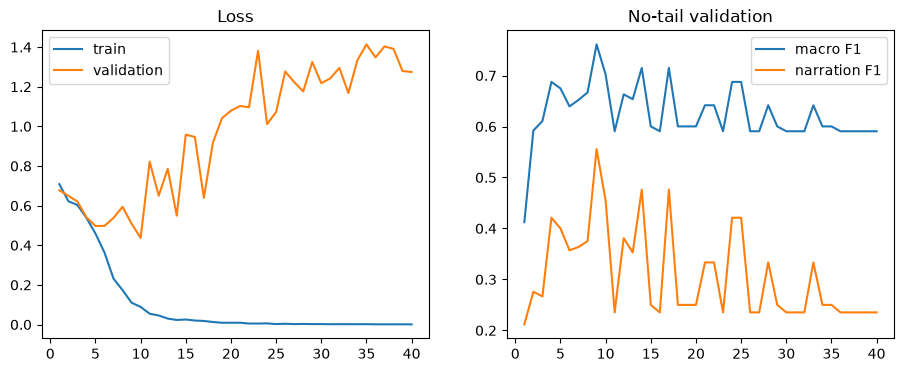

Checkpoint: C:\Users\ESHAAN\BYTE\Applied-Task\Magi\FINETUNING-EXPERMENTS\ContourNarrationMLP\runs\baseline_seed42\best.pt
Predictions: C:\Users\ESHAAN\BYTE\Applied-Task\Magi\FINETUNING-EXPERMENTS\ContourNarrationMLP\runs\baseline_seed42\val_predictions.csv


In [10]:
best=torch.load(RUN/'best.pt',map_location='cpu',weights_only=True)
assert best['contract']==TRAINING_CONTRACT,'Checkpoint feature contract mismatch'
model.load_state_dict(best['state_dict'])
mean_device=best['mean'].to(DEVICE);std_device=best['std'].to(DEVICE)
metrics,predictions=evaluate(model,val)
overall=score_predictions(predictions,include_tail=True)
heuristic=[dict(r,prediction=0 if r['heuristic_role']=='SPOKEN' else 1) for r in predictions]
heuristic_metrics=score_predictions(heuristic)
display(pd.DataFrame([dict(method='Contour heuristic, no tail',**heuristic_metrics),
    dict(method='MLP, no tail',**metrics),dict(method='MLP + forced tails, all known units',**overall)]))
save_json(RUN/'evaluation.json',dict(best_epoch=int(best['epoch']),no_tail=metrics,overall=overall,
    contour_baseline=heuristic_metrics))
pd.DataFrame(predictions).to_csv(RUN/'val_predictions.csv',index=False)
save_json(RUN/'val_predictions.json',predictions)
if history:
    frame=pd.DataFrame(history)
    fig,axes=plt.subplots(1,2,figsize=(11,4))
    axes[0].plot(frame.epoch,frame.train_loss,label='train');axes[0].plot(frame.epoch,frame.val_loss,label='validation')
    axes[0].set_title('Loss');axes[0].legend()
    axes[1].plot(frame.epoch,frame.val_macro_f1,label='macro F1')
    axes[1].plot(frame.epoch,frame.val_narrated_f1,label='narration F1');axes[1].legend();axes[1].set_title('No-tail validation')
    plt.show();plt.close(fig)
print('Checkpoint:',RUN/'best.pt')
print('Predictions:',RUN/'val_predictions.csv')
